# Compare two stimulus conditions with TRIBE

Supply a CSV with `stimulus` and `condition` columns. This notebook synthesizes English speech, predicts each stimulus separately, and plots **mean response in condition A minus mean response in condition B**.

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from tribev2.demo_utils import TribeModel
from tribev2.plotting import PlotBrainNilearn

# Works from the project root or the notebook folder.
folder = Path.cwd()
if not (folder / "utils.py").exists():
    folder = folder / "virtual_langloc"
sys.path.insert(0, str(folder.parent))
from virtual_langloc.utils import prepare_audio, stimulus_events

## Choose your stimuli

Change the CSV path and the two condition names. Rows can have different lengths and the conditions can have different numbers of stimuli.

In [7]:
condition_a = "S"
condition_b = "WL"
stimuli = pd.read_csv(folder / "stimuli.csv", dtype=str, keep_default_na=False)

if not {"stimulus", "condition"}.issubset(stimuli.columns):
    raise ValueError("CSV needs stimulus and condition columns.")
if stimuli[["stimulus", "condition"]].apply(lambda column: column.str.strip().eq("")).any().any():
    raise ValueError("Stimuli and condition labels cannot be blank.")
if condition_a == condition_b or set(stimuli.condition) != {condition_a, condition_b}:
    raise ValueError("Choose the two condition names exactly as written in the CSV.")
display(stimuli.groupby("condition").size().rename("stimuli"))

condition
S     24
WL    24
Name: stimuli, dtype: int64

## Load TRIBE and prepare speech

Audio and word timings are cached. Alignment uses the original text, so speech recognition cannot silently change a stimulus.

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
cache = folder / "cache" / "simple_comparison"
model = TribeModel.from_pretrained(
    "facebook/tribev2", cache_folder=cache, device=device,
    config_update={f"data.{name}_feature.device": device for name in ("text", "audio")},
)
model.data.batch_size = 1
model.data.num_workers = 0
model.remove_empty_segments = False
items = prepare_audio(stimuli, cache / "audio")

/storage/home/hcoda1/4/jdecker37/miniconda3/envs/virtual_neuro/lib/python3.11/site-packages/neuralset/extractors/base.py:707: UserWarning: LabelEncoder: event_types has not been set, are you sure you want to apply this extractor to all events?
  warnings.warn(
2026-10-26 14:10:09 - WARNING - neuralset.extractors.base:798 - Missing events will be encoded using the default all-zero value (for example, 0 or a zero vector/tensor), which may be indistinguishable from a valid class if that class is also mapped to zeros. Set treat_missing_as_separate_class=True to avoid this.
INFO - Loading model from /storage/home/hcoda1/4/jdecker37/.cache/huggingface/hub/models--facebook--tribev2/snapshots/f894e783020944dcd96e5568550afe2aa9743f9f/best.ckpt
 Downloaded aiohttp
 Downloaded hf-xet
 Downloaded pillow
 Downloaded grpcio
 Downloaded sqlalchemy
 Downloaded nltk
 Downloaded ctranslate2
 Downloaded fonttools
 Downloaded onnxruntime
 Downloaded pandas
Installed 118 packages in 31.38s


## Average each stimulus's predicted response

Each stimulus is placed 16 seconds into its own model window. For each vertex, average the predictions over the clip-duration interval **starting at onset + the checkpoint's BOLD offset** (normally 5 seconds). This is a simple lag-aligned average, not the full post-stimulus response or a baseline-subtracted response.

Each stimulus contributes one vector to the condition mean, regardless of its duration. Clips must fit in one model window with padding. This straightforward loop predicts stimuli separately and can be slow on CPU.

In [8]:
responses = []
window = model.data.duration_trs * model.data.TR
lag = model.data.neuro.offset

for item in tqdm(items, desc="Predicting stimuli"):
    events, onset, duration = stimulus_events(item, window)
    predictions, segments = model.predict(events=events, verbose=False)
    bold_times = np.array([segment.start for segment in segments]) + lag
    selected = (bold_times >= onset + lag) & (bold_times < onset + duration + lag)
    if not selected.any() or not np.isfinite(predictions[selected]).all():
        raise ValueError(f"No valid response samples for: {item['text']}")
    responses.append(predictions[selected].mean(axis=0))

responses = np.stack(responses)  # stimuli × cortical vertices
mean_a = responses[stimuli.condition.eq(condition_a)].mean(axis=0)
mean_b = responses[stimuli.condition.eq(condition_b)].mean(axis=0)
difference = mean_a - mean_b

Predicting stimuli:   0%|          | 0/48 [00:00<?, ?it/s][14:12:43 WARNING] Removing extractor video as there are no corresponding events
[14:12:43 INFO] Preparing extractor: text







Loading weights: 100%|██████████| 254/254 [00:00<00:00, 755.67it/s]


100%|██████████| 12/12 [00:43<00:00,  3.64s/it]

Computing word embeddings: 100%|██████████| 3/3 [00:43<00:00, 14.56s/it]
[14:13:28 INFO] Preparing extractor: audio
Loading weights: 100%|██████████| 773/773 [00:00<00:00, 1604.23it/s]
[14:13:40 INFO] Preparing extractor: subject_id
2026-10-26 14:13:40 - WARNING - neuralset.extractors.base:824 - LabelEncoder has only found one label: {'default'}. This was probably not intended.
[14:13:40 INFO] Building dataloader for split all
INFO - Predicted 100 / 100 segments (100.0% kept)
Predicting stimuli:   2%|▏         | 1/48 [00:59<46:24, 59.24s/it][14:13:43 WARNING] Removing extractor video as there are no corresponding events
[14:13:43 INFO] Preparing extractor: text



Loading weights: 100

## Plot the difference

Red means a greater predicted response to condition A; blue means a greater response to condition B. Every value is shown, without thresholding. Units are the model's normalized BOLD units, not z statistics or percent signal change.

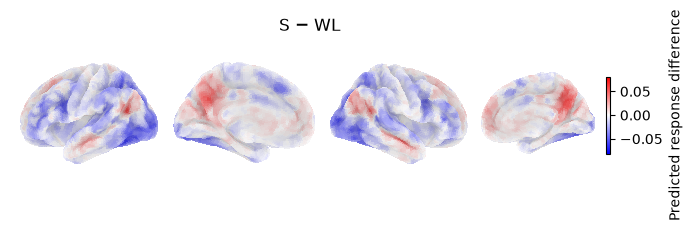

In [9]:
plotter = PlotBrainNilearn(mesh="fsaverage5")
views = ["left", "medial_left", "right", "medial_right"]
limit = max(float(np.abs(difference).max()), 1e-8)
fig, axes = plotter.get_fig_axes(views)
plotter.plot_surf(
    difference, axes=axes, views=views, cmap="bwr",
    vmin=-limit, vmax=limit, symmetric_cbar=True,
    threshold=None, colorbar=True, colorbar_title="Predicted response difference",
)
fig.suptitle(f"{condition_a} − {condition_b}")
plt.show()

np.savez_compressed(cache / "responses.npz", responses=responses,
                    mean_a=mean_a, mean_b=mean_b, difference=difference,
                    condition_a=condition_a, condition_b=condition_b)
stimuli.to_csv(cache / "stimuli.csv", index=False)
fig.savefig(cache / "difference.png", dpi=200, bbox_inches="tight")